# Gamma Recovery — End-to-End Test

Generates 500 mock clusters with a known pivot–magnitude-gap power-law index γ,
saves the truth catalog, runs the destacking likelihood through the nautilus
nested sampler, and plots the recovered posterior against the injected value.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.table import Table

from destacking.simulation import generate_truth_catalog, make_test_data
from destacking.fitting import run_sampler

Lookup tables loaded!


## Parameters

In [2]:
N_CLUSTERS    = 1000
TRUE_GAMMA    = .0      # the parameter to recover
RADII         = np.logspace(-0.6, 0.6, 8)   # projected radii in Mpc
SEED          = 42

## 1 — Generate truth catalog and save to FITS

In [3]:
truth = generate_truth_catalog(
    N_CLUSTERS,
    z_range=(0.1, 0.6),
    logM_range=(13.5, 15.0),
    delta_m_gamma=TRUE_GAMMA,
    scatter_logc=0.1,                  # zero-scatter sanity check (fix #1)
    seed=SEED,
)

truth.write('truth_catalog.fits', overwrite=True)
print(f'Saved {N_CLUSTERS} clusters  |  true γ = {TRUE_GAMMA}')
truth[:5]

Saved 1000 clusters  |  true γ = 0.0


z,M_halo,concentration,M_BCG,L_BCG,L_brightest_sat,delta_m,N_sat
float64,float64,float64,float64,float64,float64,float64,int64
0.48697802427798165,39182727136179.15,4.558408575660943,192113784331.41544,1192278412.6160085,353256548.7470639,1.3207186476297383,1
0.3194392198760262,153954739179075.25,4.05827027739552,647390990881.644,5355628940.811851,2434776212.323202,0.8558785742003233,4
0.5292989599556912,49379317814942.945,4.479553411238699,198158883415.20966,1256839141.9434001,392595692.8646215,1.263335417161642,1
0.14708867394382477,280817532884735.12,3.4952381237673964,491430313195.8166,4134994689.161528,1455704478.52946,1.1335043449189066,4
0.5878111758183779,122854505263835.72,2.7167715709375497,457514153557.82806,3842250723.094609,3553880131.435074,0.08470731392771785,2


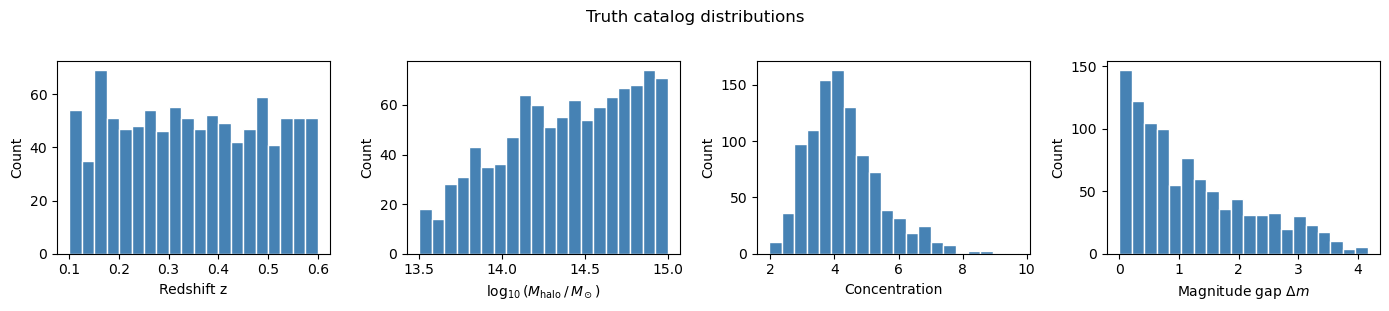

In [4]:
# Quick look at the truth distributions
fig, axes = plt.subplots(1, 4, figsize=(14, 3))

axes[0].hist(truth['z'], bins=20, color='steelblue', edgecolor='white')
axes[0].set_xlabel('Redshift z')

axes[1].hist(np.log10(truth['M_halo']), bins=20, color='steelblue', edgecolor='white')
axes[1].set_xlabel(r'$\log_{10}(M_{\rm halo}\,/\,M_\odot)$')

axes[2].hist(truth['concentration'], bins=20, color='steelblue', edgecolor='white')
axes[2].set_xlabel('Concentration')

dm = truth['delta_m']
axes[3].hist(dm[~np.isnan(dm)], bins=20, color='steelblue', edgecolor='white')
axes[3].set_xlabel(r'Magnitude gap $\Delta m$')

for ax in axes:
    ax.set_ylabel('Count')
plt.suptitle('Truth catalog distributions', y=1.02)
plt.tight_layout()
plt.show()

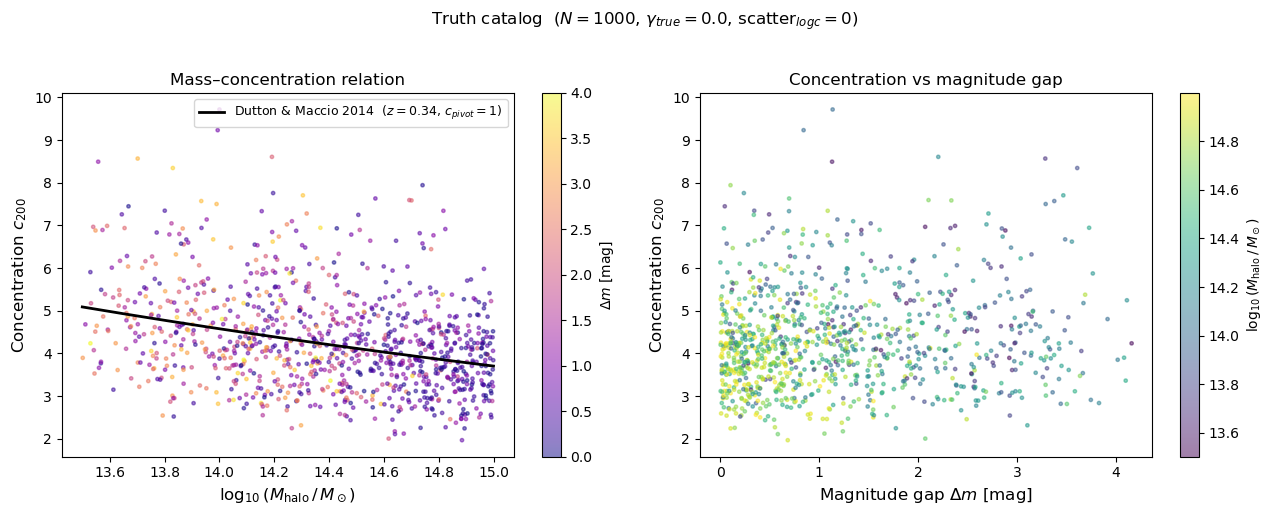

In [5]:
from destacking.relations import c_DuttonMaccio

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# --- Panel 1: M–c relation ---
ax = axes[0]
sc = ax.scatter(
    np.log10(truth['M_halo']), truth['concentration'],
    c=truth['delta_m'], cmap='plasma', s=6, alpha=0.5, vmin=0, vmax=4,
    rasterized=True,
)
plt.colorbar(sc, ax=ax, label=r'$\Delta m$ [mag]')

z_med = float(np.median(truth['z']))
M_curve = np.logspace(13.5, 15.0, 200)
C_curve = c_DuttonMaccio(z_med * np.ones(200), M_curve)
ax.plot(np.log10(M_curve), C_curve, 'k-', lw=2,
        label=rf'Dutton & Maccio 2014  ($z={z_med:.2f}$, $c_{{pivot}}=1$)')

ax.set_xlabel(r'$\log_{10}(M_{\rm halo}\,/\,M_\odot)$', fontsize=12)
ax.set_ylabel(r'Concentration $c_{200}$', fontsize=12)
ax.set_title('Mass–concentration relation', fontsize=12)
ax.legend(fontsize=9)

# --- Panel 2: c vs Δm ---
ax = axes[1]
sc2 = ax.scatter(
    truth['delta_m'], truth['concentration'],
    c=np.log10(truth['M_halo']), cmap='viridis', s=6, alpha=0.5,
    rasterized=True,
)
plt.colorbar(sc2, ax=ax, label=r'$\log_{10}(M_{\rm halo}\,/\,M_\odot)$')

ax.set_xlabel(r'Magnitude gap $\Delta m$ [mag]', fontsize=12)
ax.set_ylabel(r'Concentration $c_{200}$', fontsize=12)
ax.set_title(r'Concentration vs magnitude gap', fontsize=12)

plt.suptitle(
    rf'Truth catalog  ($N={N_CLUSTERS}$, $\gamma_{{true}}={TRUE_GAMMA}$, scatter$_{{logc}}=0$)',
    y=1.02, fontsize=12,
)
plt.tight_layout()
plt.show()

## 2 — Build synthetic observed data

In [6]:
cluster_obs, data_vectors, cov_matrices = make_test_data(
    truth,
    RADII,
    fractional_noise=0.2,
    seed=SEED + 1,
)

print(f'Observable table: {cluster_obs.colnames}')
print(f'Data shape:       {data_vectors.shape}')
print(f'Richness range:   {cluster_obs["Lambda"].min():.1f} – {cluster_obs["Lambda"].max():.1f}')
cluster_obs[:5]

Observable table: ['z', 'Lambda', 'delta_m']
Data shape:       (1000, 8)
Richness range:   3.0 – 120.0


z,Lambda,delta_m
float64,float64,float64
0.48697802427798165,12.0,1.3207186476297383
0.3194392198760262,16.0,0.8558785742003233
0.5292989599556912,4.0,1.263335417161642
0.14708867394382477,39.0,1.1335043449189066
0.5878111758183779,24.0,0.08470731392771785


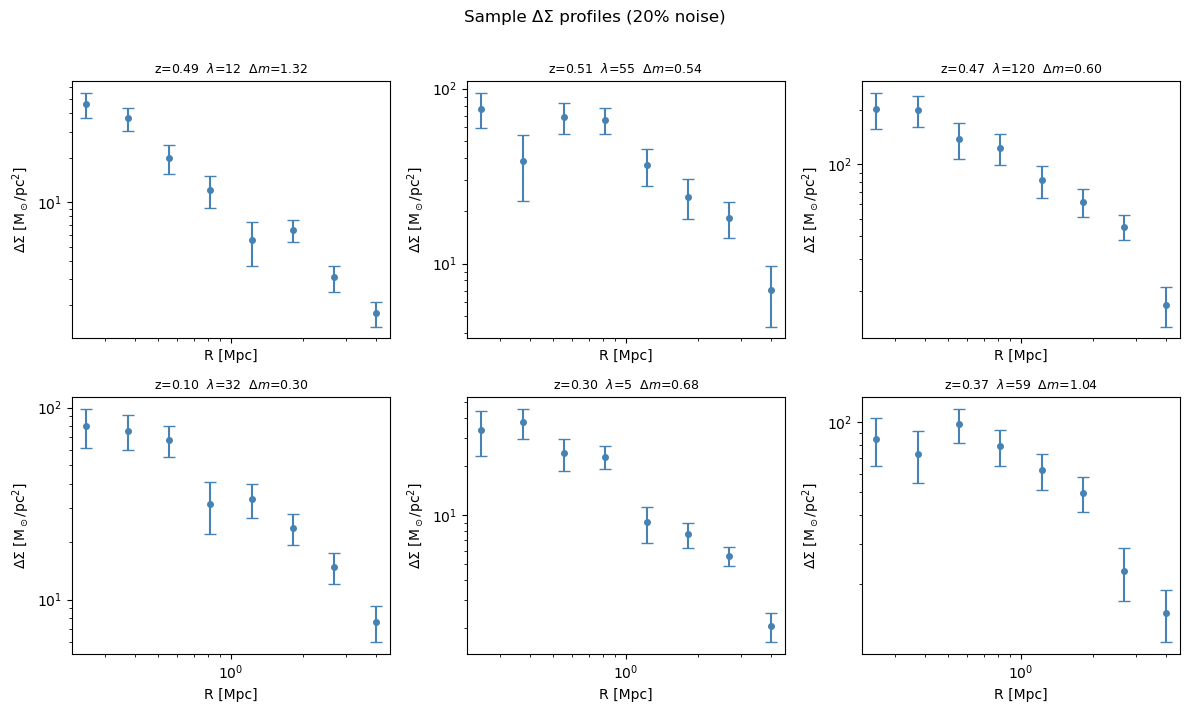

In [7]:
# Sanity check — plot six example profiles
idx = np.round(np.linspace(0, N_CLUSTERS - 1, 6)).astype(int)
fig, axes = plt.subplots(2, 3, figsize=(12, 7), sharex=True)

for ax, i in zip(axes.ravel(), idx):
    errs = np.sqrt(np.diag(cov_matrices[i]))
    ax.errorbar(RADII, data_vectors[i], yerr=errs,
                fmt='o', markersize=4, capsize=4, color='steelblue')
    ax.set_xscale('log')
    ax.set_yscale('log')
    dm_str = f'{cluster_obs["delta_m"][i]:.2f}' if np.isfinite(cluster_obs['delta_m'][i]) else 'nan'
    ax.set_title(
        f'z={cluster_obs["z"][i]:.2f}  '
        rf'$\lambda$={cluster_obs["Lambda"][i]:.0f}  '
        rf'$\Delta m$={dm_str}',
        fontsize=9,
    )
    ax.set_xlabel('R [Mpc]')
    ax.set_ylabel(r'$\Delta\Sigma$ [M$_\odot$/pc$^2$]')

plt.suptitle('Sample ΔΣ profiles (20% noise)', y=1.01)
plt.tight_layout()
plt.show()

## 3 — Run the sampler

In [8]:
sampler = run_sampler(
    cluster_obs,
    data_vectors,
    cov_matrices,
    RADII,
    gamma_range=(0.0, 3.0),
    n_live=500,
    verbose=True,
    pool=15,
)

Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    
Finished  | 17     | 1        | 4        | 16170    | N/A    | 10080 | -30398.22


## 4 — Posterior and recovery plot

In [9]:
points, log_w, log_l = sampler.posterior()
gamma_samples = points[:, 0]
weights       = np.exp(log_w - log_w.max())   # numerically stable normalisation
weights      /= weights.sum()


def weighted_quantile(values, quantiles, weights):
    """Weighted quantiles via sorted cumulative sum."""
    sorter = np.argsort(values)
    v = values[sorter]
    w = weights[sorter]
    cumw = np.cumsum(w) / np.sum(w)
    return np.interp(quantiles, cumw, v)


glo, gmd, ghi = weighted_quantile(gamma_samples, [0.16, 0.50, 0.84], weights)
print(f'True γ  : {TRUE_GAMMA}')
print(f'Recovered: {gmd:.3f}  −{gmd - glo:.3f}  +{ghi - gmd:.3f}')

True γ  : 0.0
Recovered: 0.043  −0.028  +0.034


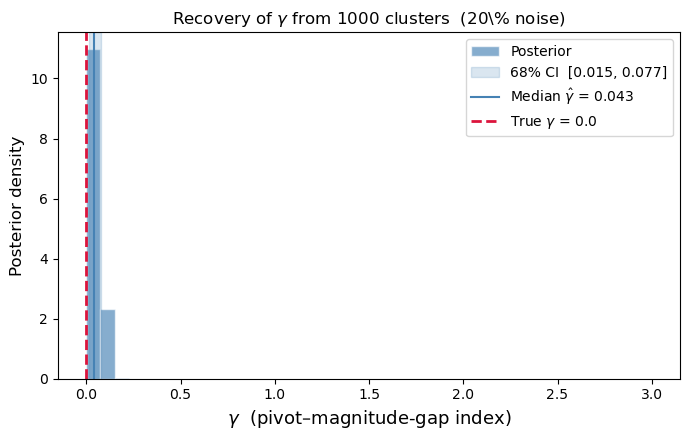

In [10]:
fig, ax = plt.subplots(figsize=(7, 4.5))

ax.hist(
    gamma_samples, weights=weights, bins=40, density=True,
    color='steelblue', alpha=0.65, edgecolor='white', label='Posterior',
)
ax.axvspan(
    glo, ghi, alpha=0.20, color='steelblue',
    label=rf'68% CI  [{glo:.3f}, {ghi:.3f}]',
)
ax.axvline(gmd,       color='steelblue', lw=1.5, ls='-',
           label=rf'Median $\hat{{\gamma}}$ = {gmd:.3f}')
ax.axvline(TRUE_GAMMA, color='crimson',   lw=2.0, ls='--',
           label=rf'True $\gamma$ = {TRUE_GAMMA}')

ax.set_xlabel(r'$\gamma$  (pivot–magnitude-gap index)', fontsize=13)
ax.set_ylabel('Posterior density', fontsize=12)
ax.set_title(
    rf'Recovery of $\gamma$ from {N_CLUSTERS} clusters  '
    rf'(20\% noise)',
    fontsize=12,
)
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig(f'gamma_posterior_{TRUE_GAMMA}.png', dpi=150)
plt.show()